In [1]:
!pip install pandas numpy matplotlib seaborn
import sys
!{sys.executable} -m pip install pandas numpy matplotlib seaborn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
data = pd.read_csv(r"D:\PROJECT MCI\MODUL 1\df_selected_cleaned.csv")

### **Persiapan Apache Spark**
---

Karena tugas mengharuskan penggunaan Spark untuk memproses dataset besar, kita perlu menginstal `pyspark` terlebih dahulu.

In [3]:
!pip install pyspark


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
# Inisialisasi Spark Session
import sys
!{sys.executable} -m pip install pyspark
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, udf
from pyspark.sql.types import StringType

spark = SparkSession.builder \
    .appName("SteamReviewAnalysis") \
    .master("local[2]") \
    .config("spark.driver.memory", "8g") \
    .config("spark.sql.shuffle.partitions", "4") \
    .config("spark.driver.maxResultSize", "4g") \
    .getOrCreate() 


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
# Load data ke Spark DataFrame
print(data.columns.tolist())

['game_name', 'username', 'review', 'review_cleaned']


In [6]:
# Pilih kolom yang relevan untuk analisis

print("\n-----------------------------------------------")
print("--- Membuat Spark DataFrame ---")
print("-----------------------------------------------")
spark_df = spark.createDataFrame(data[['game_name', 'username', 'review_cleaned']])

spark_df.show(5)


-----------------------------------------------
--- Membuat Spark DataFrame ---
-----------------------------------------------
+--------------------+--------------------+--------------------+
|           game_name|            username|      review_cleaned|
+--------------------+--------------------+--------------------+
|Warhammer 40,000:...|Sentinowl\n224 pr...|the game itself b...|
|Warhammer 40,000:...|userpig\n248 prod...|never care much a...|
|Warhammer 40,000:...|Imparat0r\n112 pr...|salute to all the...|
|Warhammer 40,000:...|      Fattest_falcon|this game feel li...|
|Warhammer 40,000:...|Jek\n410 products...|reminds me of som...|
+--------------------+--------------------+--------------------+
only showing top 5 rows



In [ ]:
from pyspark.sql.functions import regexp_replace, split

# Bersihkan kolom 'username' dengan mengambil hanya teks sebelum '\n'
print("\n-----------------------------------------------")
print("--- Membersihkan Kolom 'username' ---")
print("-----------------------------------------------")
spark_df = spark_df.withColumn('username', split(col('username'), '\n')[0])
spark_df.show(5)

26/04/26 21:51:03 WARN TaskSetManager: Stage 1 contains a task of very large size (193348 KiB). The maximum recommended task size is 1000 KiB.


+--------------------+--------------+--------------------+
|           game_name|      username|      review_cleaned|
+--------------------+--------------+--------------------+
|Warhammer 40,000:...|     Sentinowl|the game itself b...|
|Warhammer 40,000:...|       userpig|never care much a...|
|Warhammer 40,000:...|     Imparat0r|salute to all the...|
|Warhammer 40,000:...|Fattest_falcon|this game feel li...|
|Warhammer 40,000:...|           Jek|reminds me of som...|
+--------------------+--------------+--------------------+
only showing top 5 rows


# **Text Processing (tokenization )**
---

In [ ]:
from pyspark.ml.feature import RegexTokenizer

# Tokenisasi kolom 'review_cleaned' menjadi kata-kata individual
tokenizer = RegexTokenizer(
    inputCol='review_cleaned',
    outputCol='tokens',
    pattern='\\s+'
)

print("\n-----------------------------------------------")
print("--- Tokenisasi Kolom 'review_cleaned' ---")
print("-----------------------------------------------")

# Implementasi tokenisasi pada DataFrame
spark_df = tokenizer.transform(spark_df)
spark_df.select('game_name', 'tokens').show(5, truncate=False)

+--------------------------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

26/04/26 21:51:04 WARN TaskSetManager: Stage 2 contains a task of very large size (193348 KiB). The maximum recommended task size is 1000 KiB.
Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 233, in manager
    code = worker(sock, authenticated)
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 87, in worker
    outfile.flush()
    ~~~~~~~~~~~~~^^
BrokenPipeError: [Errno 32] Broken pipe


# **Implementasi TF-IDF**
---

In [ ]:
from pyspark.ml.feature import NGram

# Ekstraksi bigram (n=2) dari kolom 'tokens'
print("\n-----------------------------------------------")
print("--- Ekstraksi Bigram ---")
print("-----------------------------------------------")

ngram = NGram(n=2, inputCol='tokens', outputCol='bigrams')
spark_df = ngram.transform(spark_df)
spark_df.select('game_name', 'bigrams').show(5, truncate=False)

Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 233, in manager
    code = worker(sock, authenticated)
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 87, in worker
    outfile.flush()
    ~~~~~~~~~~~~~^^
BrokenPipeError: [Errno 32] Broken pipe
26/04/26 21:51:04 WARN TaskSetManager: Stage 3 contains a task of very large size (193348 KiB). The maximum recommended task size is 1000 KiB.


+--------------------------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 233, in manager
    code = worker(sock, authenticated)
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 87, in worker
    outfile.flush()
    ~~~~~~~~~~~~~^^
BrokenPipeError: [Errno 32] Broken pipe


In [ ]:
import pyspark
print(pyspark.__version__)

4.1.1


In [ ]:
import os
import sys

# Inisialisasi Spark Session untuk menghindari masalah memori

os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable

spark = SparkSession.builder \
    .appName("SteamReviewAnalysis") \
    .master("local[2]") \
    .config("spark.driver.memory", "8g") \
    .config("spark.sql.shuffle.partitions", "4") \
    .config("spark.driver.maxResultSize", "4g") \
    .config("spark.sql.execution.pyspark.udf.faulthandler.enabled", "true") \
    .config("spark.python.worker.faulthandler.enabled", "true") \
    .getOrCreate()

26/04/26 21:51:04 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


In [ ]:
from pyspark.ml.feature import CountVectorizer, IDF
from pyspark.sql.types import ArrayType, StringType
from pyspark.sql.functions import udf, col

# Hitung unigram IDF 
cv_unigram = CountVectorizer(inputCol='tokens', outputCol='rawUnigramFeatures', minDF=5)
cv_unigram_model = cv_unigram.fit(spark_df)
unigram_idf_model = IDF(inputCol='rawUnigramFeatures', outputCol='unigramFeatures').fit(
    cv_unigram_model.transform(spark_df)
)
unigram_idf_values = unigram_idf_model.idf.toArray()
unigram_vocab = cv_unigram_model.vocabulary
unigram_vocab_index = {w: i for i, w in enumerate(unigram_vocab)}

# Filter bigram yang komponen katanya IDF rendah
def filter_bigrams(bigrams):
    result = []
    for bigram in bigrams:
        words = bigram.split()
        if all(
            unigram_vocab_index.get(w, -1) == -1 or
            unigram_idf_values[unigram_vocab_index[w]] >= 3.0
            for w in words
        ):
            result.append(bigram)
    return result

filter_bigram_udf = udf(filter_bigrams, ArrayType(StringType()))
spark_df = spark_df.withColumn('bigrams', filter_bigram_udf(col('bigrams')))

26/04/26 21:51:04 WARN TaskSetManager: Stage 4 contains a task of very large size (193348 KiB). The maximum recommended task size is 1000 KiB.
26/04/26 21:51:13 WARN TaskSetManager: Stage 8 contains a task of very large size (193348 KiB). The maximum recommended task size is 1000 KiB.


In [ ]:
from pyspark.sql.functions import concat

# Gabungkan tokens dan bigrams yang sudah difilter
print("\n-----------------------------------------------")
print("--- Gabungkan Tokens dan Bigrams ---")
print("-----------------------------------------------")

spark_df = spark_df.withColumn('tokens_combined',
    concat(col('tokens'), col('bigrams')))
spark_df.select('game_name', 'tokens_combined').show(5, truncate=False)

26/04/26 21:51:24 WARN TaskSetManager: Stage 10 contains a task of very large size (193348 KiB). The maximum recommended task size is 1000 KiB.


+--------------------------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Traceback (most recent call last):                                              
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 233, in manager
    code = worker(sock, authenticated)
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 87, in worker
    outfile.flush()
    ~~~~~~~~~~~~~^^
BrokenPipeError: [Errno 32] Broken pipe


In [ ]:
from pyspark.sql.functions import explode

# Hitung jumlah kata unik dalam kolom 'tokens_combined'
unique_words = spark_df.select(explode(col('tokens_combined')).alias('word')).distinct().count()
print(f"Jumlah kata unik: {unique_words}")

26/04/26 21:51:25 WARN TaskSetManager: Stage 11 contains a task of very large size (193348 KiB). The maximum recommended task size is 1000 KiB.


Jumlah kata unik: 3313868


In [ ]:
from pyspark.ml.feature import HashingTF, IDF

# Menggunakan HashingTF untuk menghitung TF, lalu IDF untuk menghitung TF-IDF
print("\n-----------------------------------------------")  
print("--- Hitung TF-IDF untuk Kolom 'tokens_combined' ---")
print("-----------------------------------------------")

hashingTF = HashingTF(inputCol='tokens_combined', outputCol='rawFeatures', numFeatures=500000)
featurized_df = hashingTF.transform(spark_df)
idf = IDF(inputCol='rawFeatures', outputCol='features', minDocFreq=5)
idf_model = idf.fit(featurized_df)
tfidf_df = idf_model.transform(featurized_df)
tfidf_df.select('game_name', 'tokens_combined', 'features').show(5, truncate=False)

26/04/26 21:52:05 WARN TaskSetManager: Stage 17 contains a task of very large size (193348 KiB). The maximum recommended task size is 1000 KiB.
26/04/26 21:52:29 WARN DAGScheduler: Broadcasting large task binary with size 7.7 MiB
26/04/26 21:52:29 WARN TaskSetManager: Stage 19 contains a task of very large size (193348 KiB). The maximum recommended task size is 1000 KiB.


+--------------------------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 233, in manager
    code = worker(sock, authenticated)
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 87, in worker
    outfile.flush()
    ~~~~~~~~~~~~~^^
BrokenPipeError: [Errno 32] Broken pipe


In [ ]:
# Analisis distribusi nilai IDF
print("\n-----------------------------------------------")
print("--- Analisis Distribusi Nilai IDF ---")
print("-----------------------------------------------")

idf_values = idf_model.idf.toArray()
print(f"IDF min: {idf_values.min():.4f}")
print(f"IDF max: {idf_values.max():.4f}")
print(f"IDF mean: {idf_values.mean():.4f}")
print(f"IDF median: {np.median(idf_values):.4f}")

IDF min: 0.0000
IDF max: 11.8510
IDF mean: 9.7985
IDF median: 11.0037


In [ ]:
from pyspark.ml.feature import HashingTF

# Lihat 20 kata dengan IDF terendah
vocab_idf = list(zip(range(len(idf_values)), idf_values))
low_idf = sorted(vocab_idf, key=lambda x: x[1])[:20]
print("\n-----------------------------------------------")
print("--- 20 Kata dengan IDF Terendah ---")
print("-----------------------------------------------")
for idx, val in low_idf:
    print(f"Index {idx}: IDF = {val:.4f}")

20 kata dengan IDF terendah:
Index 17: IDF = 0.0000
Index 21: IDF = 0.0000
Index 29: IDF = 0.0000
Index 32: IDF = 0.0000
Index 35: IDF = 0.0000
Index 60: IDF = 0.0000
Index 80: IDF = 0.0000
Index 91: IDF = 0.0000
Index 110: IDF = 0.0000
Index 113: IDF = 0.0000
Index 118: IDF = 0.0000
Index 119: IDF = 0.0000
Index 122: IDF = 0.0000
Index 144: IDF = 0.0000
Index 172: IDF = 0.0000
Index 190: IDF = 0.0000
Index 201: IDF = 0.0000
Index 209: IDF = 0.0000
Index 215: IDF = 0.0000
Index 222: IDF = 0.0000


In [ ]:
from pyspark.sql.functions import udf
from pyspark.sql.types import ArrayType, StringType

# Filter tokens berdasarkan nilai IDF
IDF_THRESHOLD = 1.0

def filter_by_idf(tokens, features):
    index_to_value = dict(zip(features.indices.tolist(), features.values.tolist()))
    result = []
    for i, token in enumerate(tokens):
        score = index_to_value.get(i, 0.0)
        if score >= IDF_THRESHOLD:
            result.append(token)
    return result

print("\n-----------------------------------------------")
print("--- Filter Tokens Berdasarkan IDF ---")
print("-----------------------------------------------")

filter_udf = udf(filter_by_idf, ArrayType(StringType()))
tfidf_df = tfidf_df.withColumn('filtered_tokens', filter_udf(col('tokens_combined'), col('features')))
tfidf_df.select('game_name', 'filtered_tokens').show(5, truncate=80)

26/04/26 21:52:29 WARN DAGScheduler: Broadcasting large task binary with size 7.7 MiB
26/04/26 21:52:30 WARN TaskSetManager: Stage 20 contains a task of very large size (193348 KiB). The maximum recommended task size is 1000 KiB.
Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 233, in manager
    code = worker(sock, authenticated)
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 87, in worker
    outfile.flush()
    ~~~~~~~~~~~~~^^
BrokenPipeError: [Errno 32] Broken pipe


+--------------------------------+---------------+
|                       game_name|filtered_tokens|
+--------------------------------+---------------+
|Warhammer 40,000: Space Marine 2|             []|
|Warhammer 40,000: Space Marine 2|             []|
|Warhammer 40,000: Space Marine 2|             []|
|Warhammer 40,000: Space Marine 2|             []|
|Warhammer 40,000: Space Marine 2|             []|
+--------------------------------+---------------+
only showing top 5 rows


Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 233, in manager
    code = worker(sock, authenticated)
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 87, in worker
    outfile.flush()
    ~~~~~~~~~~~~~^^
BrokenPipeError: [Errno 32] Broken pipe


# Penjelasan
--- 
Pendekatan ini tidak dapat digunakan secara optimal karena HashingTF mengubah kata menjadi angka index melalui proses hashing yang bersifat satu arah, sehingga index tersebut tidak bisa dilacak kembali ke kata aslinya. Oleh karena itu, metode ini diganti dengan CountVectorizer yang menyimpan vocabulary mapping, sehingga setiap index dapat dikembalikan ke kata aslinya dengan tepat.


In [ ]:
from pyspark.ml.feature import CountVectorizer, IDF

# Ganti HashingTF dengan CountVectorizer
cv = CountVectorizer(inputCol='tokens_combined', outputCol='rawFeatures', minDF=5)
cv_model = cv.fit(spark_df)
featurized_df = cv_model.transform(spark_df)

# IDF
idf = IDF(inputCol='rawFeatures', outputCol='features', minDocFreq=5)
idf_model = idf.fit(featurized_df)
tfidf_df = idf_model.transform(featurized_df)

# Vocabulary tersedia!
print("\n-----------------------------------------------")
print("--- Vocabulary dari CountVectorizer ---")
print("-----------------------------------------------")

vocab = cv_model.vocabulary
print(f"Vocabulary size: {len(vocab)}")
tfidf_df.select('game_name', 'tokens_combined', 'features').show(5, truncate=False)

26/04/26 21:52:30 WARN TaskSetManager: Stage 21 contains a task of very large size (193348 KiB). The maximum recommended task size is 1000 KiB.
26/04/26 21:52:59 WARN TaskSetManager: Stage 25 contains a task of very large size (193348 KiB). The maximum recommended task size is 1000 KiB.


Vocabulary size: 262144


26/04/26 21:53:34 WARN DAGScheduler: Broadcasting large task binary with size 4.1 MiB
26/04/26 21:53:34 WARN TaskSetManager: Stage 27 contains a task of very large size (193348 KiB). The maximum recommended task size is 1000 KiB.


+--------------------------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 233, in manager
    code = worker(sock, authenticated)
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 87, in worker
    outfile.flush()
    ~~~~~~~~~~~~~^^
BrokenPipeError: [Errno 32] Broken pipe


In [ ]:
# Menampilkan contoh token dan nilai TF-IDF untuk beberapa baris
rows = tfidf_df.select('tokens_combined', 'features').limit(5).collect()

print("\n-----------------------------------------------")
print("--- Contoh Token dan Nilai TF-IDF ---")
print("-----------------------------------------------")

for i, row in enumerate(rows):
    print(f"\nRow {i+1} :")
    print("Tokens:", row['tokens_combined'][:10])
    print("Indices:", row['features'].indices[:10])
    print("Values:", row['features'].values[:10])

26/04/26 21:53:34 WARN DAGScheduler: Broadcasting large task binary with size 4.1 MiB
26/04/26 21:53:34 WARN TaskSetManager: Stage 28 contains a task of very large size (193348 KiB). The maximum recommended task size is 1000 KiB.



Row 1 :
Tokens: ['the', 'game', 'itself', 'be', 'also', 'super', 'fun', 'the', 'pvp', 'and']
Indices: [ 0  1  2  3  4  5  7  8  9 10]
Values: [4.17451667 2.6655844  1.89139123 4.8462583  1.28485442 5.51946842
 3.0054128  1.62528482 0.98486763 2.19036847]

Row 2 :
Tokens: ['never', 'care', 'much', 'about', 'warhammer', 'until', 'this', 'game', 'show', 'me']
Indices: [ 0  1  2  3  4  5  6  8  9 10]
Values: [ 4.17451667 14.39415575  3.78278246  5.53858092  1.28485442  1.3798671
 10.73990957  3.25056964  0.98486763  4.38073693]

Row 3 :
Tokens: ['salute', 'to', 'all', 'the', 'fall', 'battle', 'brother', 'who', 'could', 'not']
Indices: [0 1 2 3 4 5 6 7 8 9]
Values: [2.78301111 2.13246752 2.52185497 1.38464523 0.42828481 0.68993355
 4.13073445 3.0054128  1.62528482 0.98486763]

Row 4 :
Tokens: ['this', 'game', 'feel', 'like', 'it', 'be', 'make', 'in', 'the', 'mid']
Indices: [ 0  1  4  5  8 10 16 20 29 35]
Values: [0.46383519 0.53311688 0.42828481 0.68993355 0.81264241 2.19036847
 1.17882885

Traceback (most recent call last):                                              
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 233, in manager
    code = worker(sock, authenticated)
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 87, in worker
    outfile.flush()
    ~~~~~~~~~~~~~^^
BrokenPipeError: [Errno 32] Broken pipe
Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 233, in manager
    code = worker(sock, authenticated)
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 87, in worker
    outfile.flush()
    ~~~~~~~~~~~~~^^
BrokenPipeError: [Errno 32] Broken pipe


In [ ]:
# Analisis distribusi nilai IDF sekali lagi untuk memastikan
print("\n-----------------------------------------------")
print("--- Analisis Distribusi Nilai IDF ---")
print("-----------------------------------------------")

idf_values = idf_model.idf.toArray()
print(f"IDF min: {idf_values.min():.4f}")
print(f"IDF max: {idf_values.max():.4f}")
print(f"IDF mean: {idf_values.mean():.4f}")
print(f"IDF median: {np.median(idf_values):.4f}")

IDF min: 0.4283
IDF max: 11.8510
IDF mean: 10.9260
IDF median: 11.2448


In [ ]:
from pyspark.ml.linalg import SparseVector

# Ekstraksi nilai TF-IDF dari SparseVector
def extract_tfidf_values(vector):
    if isinstance(vector, SparseVector):
        return vector.values.tolist()
    return vector.toArray().tolist()

sample_tfidf = tfidf_df.select('features').sample(False, 0.01, seed=42).collect()

# Kumpulkan semua nilai TF-IDF dari sampel
all_values = []
for row in sample_tfidf:
    all_values.extend(extract_tfidf_values(row.features))

tfidf_array = np.array(all_values)
print("-----------------------------------------------")
print("--- Statistik Distribusi Nilai TF-IDF Score ---")
print("-----------------------------------------------")
print(f"Min       : {tfidf_array.min():.6f}")
print(f"Max       : {tfidf_array.max():.6f}")
print(f"Mean      : {tfidf_array.mean():.6f}")
print(f"Median    : {np.median(tfidf_array):.6f}")
print(f"P25       : {np.percentile(tfidf_array, 25):.6f}")
print(f"P75       : {np.percentile(tfidf_array, 75):.6f}")
print(f"P90       : {np.percentile(tfidf_array, 90):.6f}")

ConnectionRefusedError: [Errno 61] Connection refused

In [ ]:
# Hitung threshold berdasarkan outlier boundary (Tukey's method)
idf_nonzero = idf_values[idf_values > 0]

Q1 = np.percentile(idf_nonzero, 25)
Q3 = np.percentile(idf_nonzero, 75)
IQR = Q3 - Q1
idf_threshold = Q1 - 1.5 * IQR

print("\n-----------------------------------------------")
print("--- Analisis Outlier pada Nilai IDF ---")
print("-----------------------------------------------")
print(f"Q1  : {Q1:.4f}")
print(f"Q3  : {Q3:.4f}")
print(f"IQR : {IQR:.4f}")
print(f"Threshold (Q1 - 1.5×IQR) : {idf_threshold:.4f}")
print(f"\nKata dengan IDF < {idf_threshold:.4f} dianggap outlier (stopwords otomatis)")

Q1  : 10.5982
Q3  : 11.6968
IQR : 1.0986
Threshold (Q1 - 1.5×IQR) : 8.9503

Kata dengan IDF < 8.9503 dianggap outlier (stopwords otomatis)


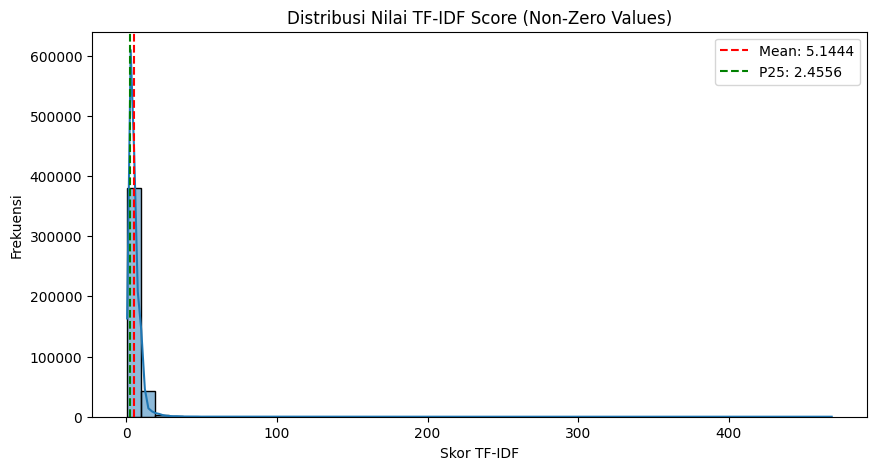

In [ ]:
import seaborn as sns

# Visualisasi distribusi nilai TF-IDF Score
plt.figure(figsize=(10, 5))
sns.histplot(tfidf_array, bins=50, kde=True)
plt.title("Distribusi Nilai TF-IDF Score (Non-Zero Values)")
plt.xlabel("Skor TF-IDF")
plt.ylabel("Frekuensi")
plt.axvline(tfidf_array.mean(), color='r', linestyle='--',
            label=f'Mean: {tfidf_array.mean():.4f}')
plt.axvline(np.percentile(tfidf_array, 25), color='green', linestyle='--',
            label=f'P25: {np.percentile(tfidf_array, 25):.4f}')
plt.legend()
plt.show()

### Kesimpulan Penentuan Threshold
---
Tukey's method menghasilkan threshold 8.95 — terlalu tinggi karena
distribusi IDF data ini sangat right-skewed (mayoritas kata IDF-nya 9-11),
bukan distribusi normal yang menjadi asumsi metode Tukey.

Threshold final = **3.0** dipilih berdasarkan:
- Inspeksi visual boxplot → kata IDF < 3.0 adalah outlier ekstrem di kiri
- Konfirmasi dari distribusi TF-IDF score → P25 = 2.46, threshold 3.0
  membuang kurang dari 25% kata terbawah
- Jauh di bawah Q1 (10.6), memastikan kata bermakna tidak terbuang

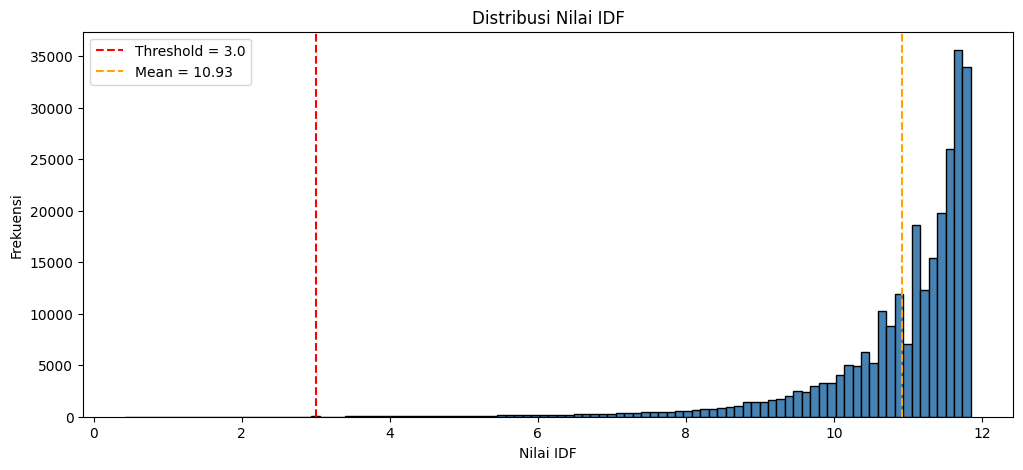

In [ ]:
# Visualisasi distribusi nilai IDF
idf_nonzero = idf_values[idf_values > 0]

plt.figure(figsize=(12, 5))
plt.hist(idf_nonzero, bins=100, color='steelblue', edgecolor='black')
plt.axvline(x=3.0, color='red', linestyle='--', label='Threshold = 3.0')
plt.axvline(x=idf_values.mean(), color='orange', linestyle='--', label=f'Mean = {idf_values.mean():.2f}')
plt.title('Distribusi Nilai IDF')
plt.xlabel('Nilai IDF')
plt.ylabel('Frekuensi')
plt.legend()
plt.show()

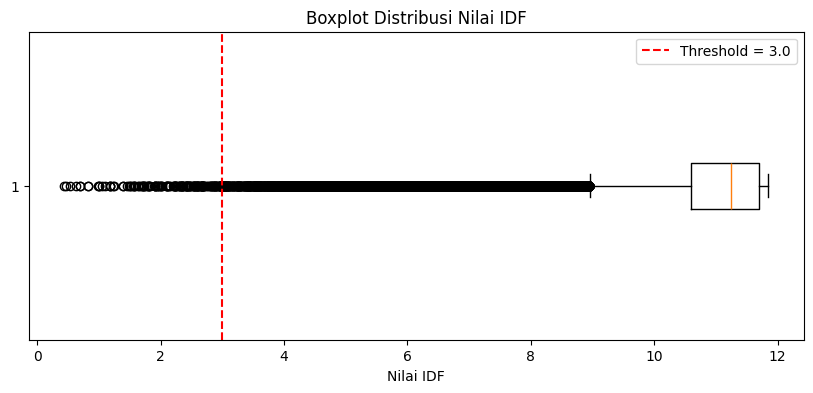

In [ ]:
# Boxplot distribusi nilai IDF
plt.figure(figsize=(10, 4))
plt.boxplot(idf_nonzero, vert=False)
plt.axvline(x=3.0, color='red', linestyle='--', label='Threshold = 3.0')
plt.title('Boxplot Distribusi Nilai IDF')
plt.xlabel('Nilai IDF')
plt.legend()
plt.show()

In [ ]:
# Filter tokens berdasarkan nilai IDF dengan threshold yang lebih masuk akal
idf_values = idf_model.idf.toArray()
IDF_THRESHOLD = 3.0
vocab = cv_model.vocabulary

# Fungsi untuk filter tokens berdasarkan nilai IDF
def filter_by_idf_value(tokens, features):
    words = []
    scores = []
    for idx, val in zip(features.indices, features.values):
        if idf_values[idx] >= IDF_THRESHOLD:
            words.append(vocab[idx])
            scores.append(float(val))  # simpan TF-IDF score nya juga
    return list(zip(words, scores))

from pyspark.sql.types import ArrayType, StructType, StructField, StringType, FloatType

# UDF untuk filter tokens berdasarkan nilai IDF dengan output berupa list of (word, score)
schema = ArrayType(StructType([
    StructField("word", StringType()),
    StructField("score", FloatType())
]))

print("\n-----------------------------------------------")
print("--- Filter Tokens Berdasarkan Nilai IDF ---")
print("-----------------------------------------------")
filter_udf = udf(filter_by_idf_value, schema)
tfidf_df = tfidf_df.withColumn('filtered_tokens', filter_udf(col('tokens_combined'), col('features')))

tfidf_df.select('game_name', 'filtered_tokens').show(5, truncate=False)

26/04/26 21:54:00 WARN DAGScheduler: Broadcasting large task binary with size 4.1 MiB
26/04/26 21:54:00 WARN TaskSetManager: Stage 30 contains a task of very large size (193348 KiB). The maximum recommended task size is 1000 KiB.


+--------------------------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 233, in manager
    code = worker(sock, authenticated)
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 87, in worker
    outfile.flush()
    ~~~~~~~~~~~~~^^
BrokenPipeError: [Errno 32] Broken pipe


In [ ]:
from pyspark.sql.types import StringType

# Fungsi untuk menghitung jumlah kata non-zero dalam fitur TF-IDF
def count_nonzero(vector):
    return float(vector.numNonzeros())

# UDF untuk menghitung jumlah kata non-zero dalam fitur TF-IDF
count_udf = udf(count_nonzero, StringType())

# Hitung jumlah kata sebelum dan sesudah filter untuk beberapa sampel
sample_counts = tfidf_df.select(
    count_udf(col('features')).alias('sebelum_filter'),
    col('filtered_tokens')
).limit(10).toPandas()

sample_counts['sesudah_filter'] = sample_counts['filtered_tokens'].apply(len)
sample_counts = sample_counts.drop(columns=['filtered_tokens'])

print("\n-----------------------------------------------")
print("--- Statistik Filter Tokens ---")
print("-----------------------------------------------")
display(sample_counts)
print(f"\nRata-rata kata sebelum filter: {sample_counts['sebelum_filter'].astype(float).mean():.1f}")
print(f"Rata-rata kata sesudah filter: {sample_counts['sesudah_filter'].mean():.1f}")
print(f"Threshold IDF = 3.0 membuang rata-rata {(sample_counts['sebelum_filter'].astype(float) - sample_counts['sesudah_filter']).mean():.1f} kata per review")

26/04/26 21:54:00 WARN DAGScheduler: Broadcasting large task binary with size 4.1 MiB
26/04/26 21:54:00 WARN TaskSetManager: Stage 31 contains a task of very large size (193348 KiB). The maximum recommended task size is 1000 KiB.
Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 233, in manager
    code = worker(sock, authenticated)
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 87, in worker
    outfile.flush()
    ~~~~~~~~~~~~~^^
BrokenPipeError: [Errno 32] Broken pipe


,sebelum_filter,sesudah_filter
0,73.0,34
1,145.0,103
2,112.0,80
3,14.0,1
4,15.0,5
5,401.0,293
6,342.0,249
7,38.0,13
8,44.0,23
9,424.0,347



Rata-rata kata sebelum filter: 160.8
Rata-rata kata sesudah filter: 114.8
Threshold IDF = 3.0 membuang rata-rata 46.0 kata per review


In [ ]:
# Hitung jumlah kata sebelum dan sesudah filter untuk beberapa sampel (0.1%)
sample_counts = tfidf_df.sample(False, 0.001, seed=42).select(
    col('game_name'),
    count_udf(col('features')).alias('sebelum_filter'),
    col('filtered_tokens')
).limit(10).toPandas()

sample_counts['sesudah_filter'] = sample_counts['filtered_tokens'].apply(len)
sample_counts = sample_counts.drop(columns=['filtered_tokens'])

print("\n-----------------------------------------------")
print("--- Statistik Filter Tokens (Sample 0.1%) ---")
print("-----------------------------------------------")
display(sample_counts)
print(f"\nRata-rata kata sebelum filter: {sample_counts['sebelum_filter'].astype(float).mean():.1f}")
print(f"Rata-rata kata sesudah filter: {sample_counts['sesudah_filter'].mean():.1f}")
print(f"Threshold IDF = 3.0 membuang rata-rata {(sample_counts['sebelum_filter'].astype(float) - sample_counts['sesudah_filter']).mean():.1f} kata per review")

26/04/26 21:54:01 WARN DAGScheduler: Broadcasting large task binary with size 4.1 MiB
26/04/26 21:54:01 WARN TaskSetManager: Stage 32 contains a task of very large size (193348 KiB). The maximum recommended task size is 1000 KiB.
Traceback (most recent call last):                                  (0 + 1) / 1]
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 233, in manager
    code = worker(sock, authenticated)
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 87, in worker
    outfile.flush()
    ~~~~~~~~~~~~~^^
BrokenPipeError: [Errno 32] Broken pipe
Traceback (most recent call last):                                              
Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py

,game_name,sebelum_filter,sesudah_filter
0,Counter-Strike 2,56.0,28
1,Counter-Strike 2,34.0,12
2,Counter-Strike 2,20.0,13
3,ELDEN RING,14.0,5
4,ELDEN RING,139.0,87
5,ELDEN RING,15.0,8
6,ELDEN RING,53.0,24
7,Total War: WARHAMMER III,23.0,11
8,Total War: WARHAMMER III,139.0,100
9,Total War: WARHAMMER III,68.0,37



Rata-rata kata sebelum filter: 56.1
Rata-rata kata sesudah filter: 32.5
Threshold IDF = 3.0 membuang rata-rata 23.6 kata per review


Kata yang tersisa adalah kata-kata yang secara statistik cukup unik untuk menjadi signature keywords.

# **Ekstraksi Signature Keywords**
---

In [ ]:
# Tampilkan contoh token dan nilai TF-IDF setelah filter

print("\n-----------------------------------------------")
print("--- Contoh Token dan Nilai TF-IDF Setelah Filter ---")
print("-----------------------------------------------")
exploded = tfidf_df.select(
    col('game_name'),
    explode(col('filtered_tokens')).alias('word_score')
).select(
    col('game_name'),
    col('word_score.word').alias('word'),
    col('word_score.score').alias('score')
)

exploded.show(10, truncate=False)

26/04/26 21:54:03 WARN DAGScheduler: Broadcasting large task binary with size 4.1 MiB
26/04/26 21:54:03 WARN TaskSetManager: Stage 33 contains a task of very large size (193348 KiB). The maximum recommended task size is 1000 KiB.


+--------------------------------+--------+---------+
|game_name                       |word    |score    |
+--------------------------------+--------+---------+
|Warhammer 40,000: Space Marine 2|point   |3.0387304|
|Warhammer 40,000: Space Marine 2|two     |3.3769116|
|Warhammer 40,000: Space Marine 2|almost  |3.3945017|
|Warhammer 40,000: Space Marine 2|campaign|3.743133 |
|Warhammer 40,000: Space Marine 2|able    |3.4684734|
|Warhammer 40,000: Space Marine 2|control |3.5292888|
|Warhammer 40,000: Space Marine 2|open    |3.5948222|
|Warhammer 40,000: Space Marine 2|etc     |3.7655694|
|Warhammer 40,000: Space Marine 2|itself  |3.7091815|
|Warhammer 40,000: Space Marine 2|super   |3.7939458|
+--------------------------------+--------+---------+
only showing top 10 rows


Traceback (most recent call last):                                              
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 233, in manager
    code = worker(sock, authenticated)
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 87, in worker
    outfile.flush()
    ~~~~~~~~~~~~~^^
BrokenPipeError: [Errno 32] Broken pipe
Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 233, in manager
    code = worker(sock, authenticated)
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 87, in worker
    outfile.flush()
    ~~~~~~~~~~~~~^^
BrokenPipeError: [Errno 32] Broken pipe
Traceback 

In [ ]:
from pyspark.sql.functions import sum as spark_sum

# Akumulasi skor TF-IDF untuk setiap kata dalam setiap game
print("\n-----------------------------------------------")
print("--- Akumulasi Skor TF-IDF per Kata per Game ---")
print("-----------------------------------------------")
accumulated = exploded.groupBy('game_name', 'word').agg(
    spark_sum('score').alias('total_score')
)

accumulated.show(10, truncate=False)

Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 233, in manager
    code = worker(sock, authenticated)
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 87, in worker
    outfile.flush()
    ~~~~~~~~~~~~~^^
BrokenPipeError: [Errno 32] Broken pipe
26/04/26 21:54:05 WARN DAGScheduler: Broadcasting large task binary with size 4.1 MiB
26/04/26 21:54:05 WARN TaskSetManager: Stage 34 contains a task of very large size (193348 KiB). The maximum recommended task size is 1000 KiB.
Traceback (most recent call last):                                  (0 + 2) / 2]
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 233, in manager
    code = worker(sock, authenticated)
  File "/Library/F

+--------------------------------+--------+------------------+
|game_name                       |word    |total_score       |
+--------------------------------+--------+------------------+
|Warhammer 40,000: Space Marine 2|campaign|3627.0959882736206|
|Warhammer 40,000: Space Marine 2|able    |461.3069667816162 |
|Warhammer 40,000: Space Marine 2|control |451.74896478652954|
|Warhammer 40,000: Space Marine 2|etc     |293.7144181728363 |
|Warhammer 40,000: Space Marine 2|super   |371.80668687820435|
|Warhammer 40,000: Space Marine 2|action  |722.0484900474548 |
|Warhammer 40,000: Space Marine 2|metal   |68.14458227157593 |
|Warhammer 40,000: Space Marine 2|weekly  |6.335510730743408 |
|Warhammer 40,000: Space Marine 2|each    |539.1887111663818 |
|Warhammer 40,000: Space Marine 2|learn   |207.87585926055908|
+--------------------------------+--------+------------------+
only showing top 10 rows


## **Identifikasi Signature Keywords per Game**
---

In [ ]:
# pipeline RDD Apache Spark

# Mapping ((game_name, word), score) per kata per review
word_rdd = exploded.rdd.map(
    lambda row: ((row['game_name'], row['word']), row['score'])
)
# ReduceByKey untuk akumulasi total skor per (game, word)
accumulated_rdd = word_rdd.reduceByKey(lambda a, b: a + b)

# Map ulang (game_name, (word, total_score))
game_word_rdd = accumulated_rdd.map(lambda x: (x[0][0], (x[0][1], x[1])))

# GroupByKey mengumpulkan semua (word, score) per game
grouped_rdd = game_word_rdd.groupByKey()

# Ambil top 3 kata per game
def get_top3(words_scores):
    sorted_ws = sorted(words_scores, key=lambda x: x[1], reverse=True)
    return [ws[0] for ws in sorted_ws[:3]]

signature_rdd = grouped_rdd.mapValues(get_top3)

# Convert ke DataFrame
print("\n-----------------------------------------------")
print("--- Hasil Signature Keywords per Game ---")
print("-----------------------------------------------")
signature_df = signature_rdd.toDF(['game_name', 'signature_keywords'])
signature_df.orderBy('game_name').show(20, truncate=False)

26/04/26 21:55:59 WARN DAGScheduler: Broadcasting large task binary with size 4.1 MiB
26/04/26 21:55:59 WARN TaskSetManager: Stage 37 contains a task of very large size (193348 KiB). The maximum recommended task size is 1000 KiB.


+--------------------------------------+-----------------------------+
|game_name                             |signature_keywords           |
+--------------------------------------+-----------------------------+
|69 Balls                              |[ball, rocket league, league]|
|7 Days to Die                         |[zombie, alpha, survival]    |
|ARK: Survival Ascended                |[ark, server, crash]         |
|ARK: Survival Evolved                 |[server, ark, tame]          |
|Age of Empires II (Retired)           |[age, hd, empire]            |
|Age of Empires II: Definitive Edition |[aoe, age, rts]              |
|Age of Empires IV: Anniversary Edition|[aoe, age, unit]             |
|Age of Mythology: Retold              |[original, aom, age]         |
|Age of Wonders 4                      |[aow, unit, wonder]          |
|Aimlabs                               |[aim, aim lab, lab]          |
|Ale & Tale Tavern                     |[tavern, quest, ale]         |
|All-I

## **Validasi Signature Keywords per Game**
---

In [ ]:
from pyspark.sql.functions import collect_list

# Pastikan signature_df sudah ada
print("\n-----------------------------------------------")
print("--- Signature Keywords per Game ---")
print("-----------------------------------------------")
signature_df.orderBy('game_name').show(20, truncate=False)
print(f"Total game: {signature_df.count()}")

+--------------------------------------+-----------------------------+
|game_name                             |signature_keywords           |
+--------------------------------------+-----------------------------+
|69 Balls                              |[ball, rocket league, league]|
|7 Days to Die                         |[zombie, alpha, survival]    |
|ARK: Survival Ascended                |[ark, server, crash]         |
|ARK: Survival Evolved                 |[server, ark, tame]          |
|Age of Empires II (Retired)           |[age, hd, empire]            |
|Age of Empires II: Definitive Edition |[aoe, age, rts]              |
|Age of Empires IV: Anniversary Edition|[aoe, age, unit]             |
|Age of Mythology: Retold              |[original, aom, age]         |
|Age of Wonders 4                      |[aow, unit, wonder]          |
|Aimlabs                               |[aim, aim lab, lab]          |
|Ale & Tale Tavern                     |[tavern, quest, ale]         |
|All-I

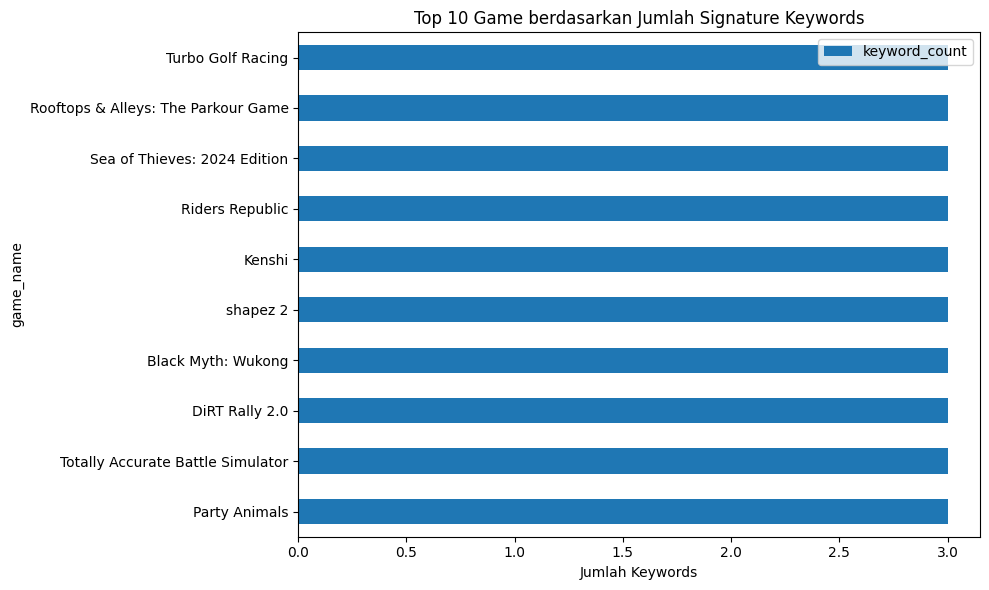

In [ ]:
# Bar chart top 10 game berdasarkan jumlah keyword unik
import matplotlib.pyplot as plt

sig_pd = signature_df.toPandas()
sig_pd['keyword_count'] = sig_pd['signature_keywords'].apply(len)

sig_pd.sort_values('keyword_count', ascending=False).head(10).plot(
    kind='barh', x='game_name', y='keyword_count', figsize=(10, 6)
)
plt.title('Top 10 Game berdasarkan Jumlah Signature Keywords')
plt.xlabel('Jumlah Keywords')
plt.tight_layout()
plt.show()

In [ ]:
!pip install wordcloud

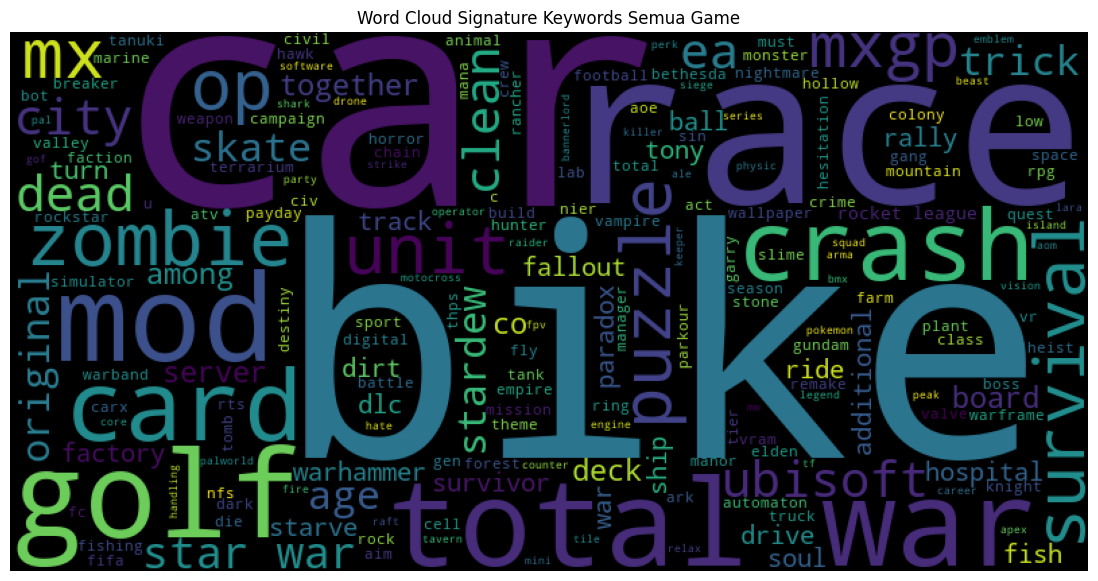

In [ ]:
from wordcloud import WordCloud

all_keywords = ' '.join([' '.join(kw) for kw in sig_pd['signature_keywords']])
wc = WordCloud(width=800, height=400, background_color='black').generate(all_keywords)
plt.figure(figsize=(15, 7))
plt.imshow(wc)
plt.axis('off')
plt.title('Word Cloud Signature Keywords Semua Game')
plt.show()

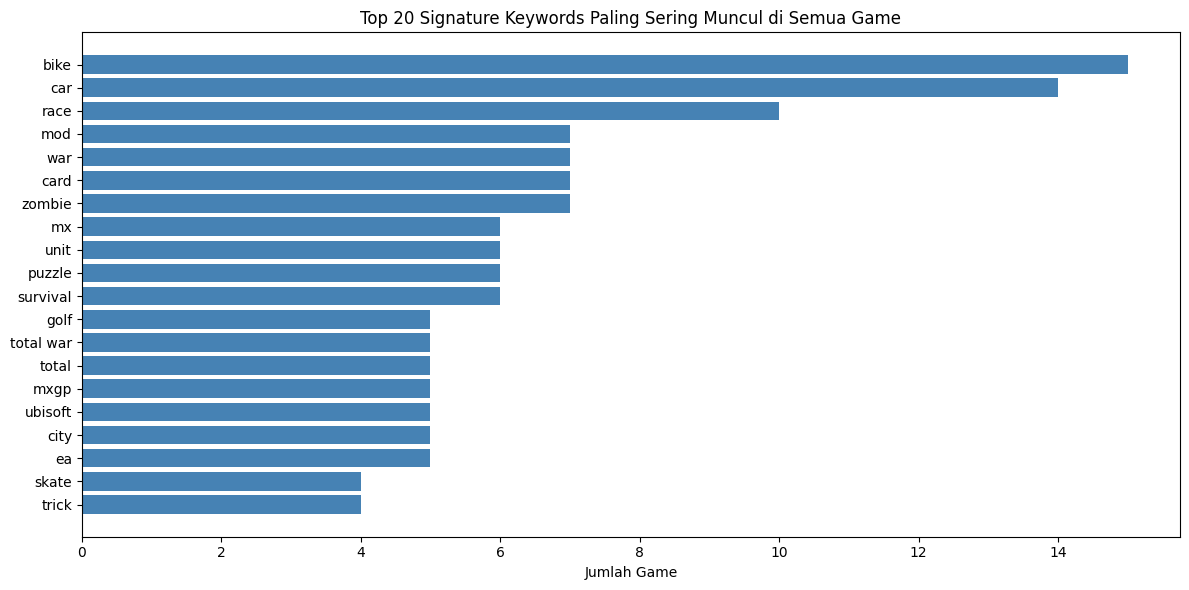

In [ ]:
from collections import Counter

all_kw_list = [kw for sublist in sig_pd['signature_keywords'] for kw in sublist]
kw_counts = Counter(all_kw_list)

top20 = pd.DataFrame(kw_counts.most_common(20), columns=['keyword', 'count'])

plt.figure(figsize=(12, 6))
plt.barh(top20['keyword'], top20['count'], color='steelblue')
plt.title('Top 20 Signature Keywords Paling Sering Muncul di Semua Game')
plt.xlabel('Jumlah Game')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
import sys
!{sys.executable} -m pip install textblob

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 625.0/625.0 kB 8.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 10.3 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [textblob]4/6 [nltk]b]


In [ ]:
from pyspark.sql.functions import udf
from pyspark.sql.types import StringType
from textblob import TextBlob

# Analisis Sentiment Review

print("\n-----------------------------------------------")
print("--- Analisis Sentiment Review ---")
print("-----------------------------------------------")

def get_sentiment(text):
    if text:
        polarity = TextBlob(text).sentiment.polarity
        if polarity > 0.1:
            return 'positive'
        elif polarity < -0.1:
            return 'negative'
        else:
            return 'neutral'
    return 'neutral'

sentiment_udf = udf(get_sentiment, StringType())
spark_df = spark_df.withColumn('sentiment', sentiment_udf(col('review_cleaned')))

# Distribusi sentiment per game
sentiment_dist = spark_df.groupBy('game_name', 'sentiment').count()
sentiment_dist.orderBy('game_name', 'sentiment').show(20, truncate=False)

26/04/26 22:08:54 WARN TaskSetManager: Stage 56 contains a task of very large size (193348 KiB). The maximum recommended task size is 1000 KiB.


+--------------------------------------+---------+-----+
|game_name                             |sentiment|count|
+--------------------------------------+---------+-----+
|69 Balls                              |negative |16   |
|69 Balls                              |neutral  |34   |
|69 Balls                              |positive |40   |
|7 Days to Die                         |negative |551  |
|7 Days to Die                         |neutral  |2911 |
|7 Days to Die                         |positive |1505 |
|ARK: Survival Ascended                |negative |1050 |
|ARK: Survival Ascended                |neutral  |2626 |
|ARK: Survival Ascended                |positive |1239 |
|ARK: Survival Evolved                 |negative |904  |
|ARK: Survival Evolved                 |neutral  |2651 |
|ARK: Survival Evolved                 |positive |1107 |
|Age of Empires II (Retired)           |negative |458  |
|Age of Empires II (Retired)           |neutral  |1545 |
|Age of Empires II (Retired)   

26/04/26 22:17:40 WARN TaskSetManager: Stage 59 contains a task of very large size (193348 KiB). The maximum recommended task size is 1000 KiB.


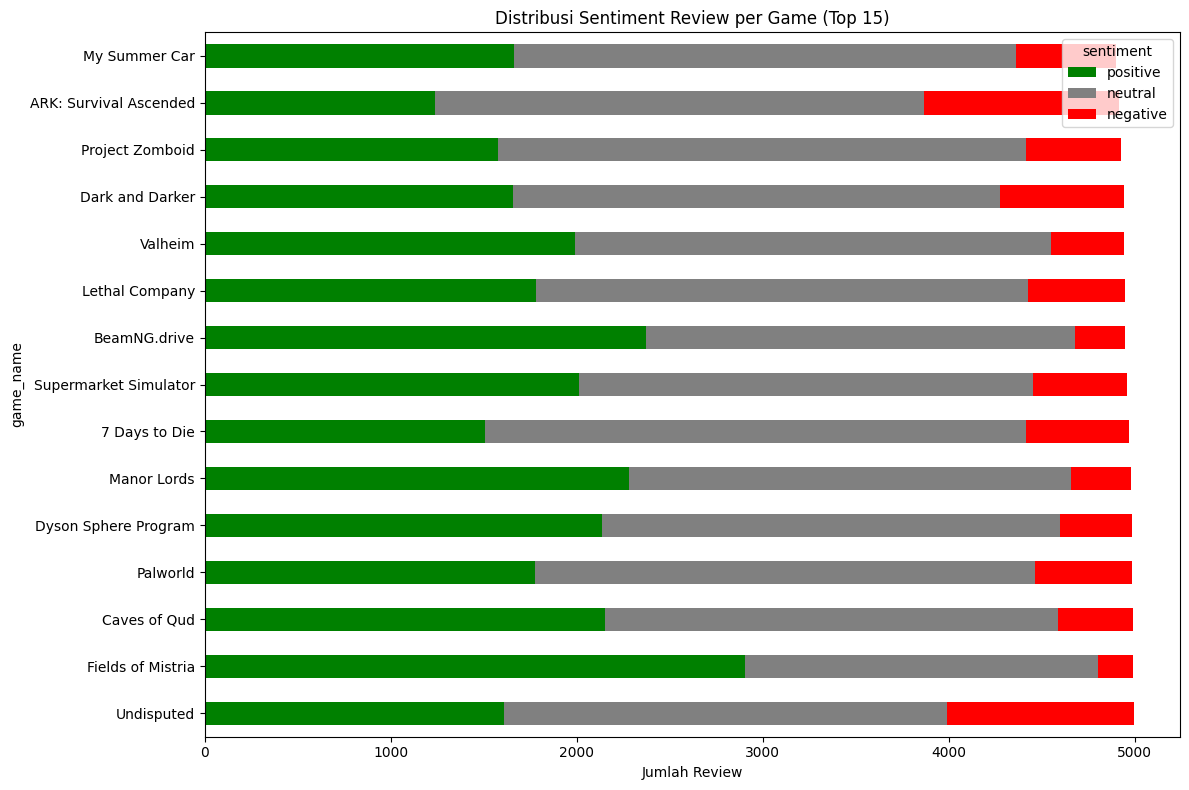

26/04/27 02:20:10 WARN HeartbeatReceiver: Removing executor driver with no recent heartbeats: 1667375 ms exceeds timeout 120000 ms
26/04/27 02:20:10 WARN SparkContext: Killing executors is not supported by current scheduler.
26/04/27 02:20:12 ERROR Inbox: Ignoring error
org.apache.spark.SparkException: Exception thrown in awaitResult: 
	at org.apache.spark.util.SparkThreadUtils$.awaitResult(SparkThreadUtils.scala:53)
	at org.apache.spark.util.ThreadUtils$.awaitResult(ThreadUtils.scala:359)
	at org.apache.spark.rpc.RpcTimeout.awaitResult(RpcTimeout.scala:75)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRefByURI(RpcEnv.scala:102)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRef(RpcEnv.scala:110)
	at org.apache.spark.util.RpcUtils$.makeDriverRef(RpcUtils.scala:36)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.driverEndpoint$lzycompute(BlockManagerMasterEndpoint.scala:132)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.org$apache$spark$storage$BlockManagerMasterEndpoint$

In [ ]:
sentiment_pd = sentiment_dist.toPandas()
sentiment_pivot = sentiment_pd.pivot(index='game_name', columns='sentiment', values='count').fillna(0)

# Ambil top 15 game terbanyak reviewnya
top_games = sentiment_pd.groupby('game_name')['count'].sum().nlargest(15).index
sentiment_pivot = sentiment_pivot.loc[top_games]

sentiment_pivot[['positive', 'neutral', 'negative']].plot(
    kind='barh', stacked=True, figsize=(12, 8),
    color=['green', 'gray', 'red']
)
plt.title('Distribusi Sentiment Review per Game (Top 15)')
plt.xlabel('Jumlah Review')
plt.tight_layout()
plt.show()